In [26]:
import numpy as np
import pandas as pd
import seaborn as sns
import random
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import ConfusionMatrixDisplay, pairwise_distances, roc_auc_score, roc_curve,r2_score, roc_auc_score, accuracy_score, confusion_matrix
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.cluster import KMeans


# Configure style
sns.set_theme(style="whitegrid")

seed = 42

framingham = pd.read_csv("../Data/framingham.csv") # load the dataset

In [3]:
framingham.head()

,Unnamed: 0,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,1,39,4,0,0,0,0,0,0,195,106.0,70.0,26.97,80,77,0
1,2,0,46,2,0,0,0,0,0,0,250,121.0,81.0,28.73,95,76,0
2,3,1,48,1,1,20,0,0,0,0,245,127.5,80.0,25.34,75,70,0
3,4,0,61,3,1,30,0,0,1,0,225,150.0,95.0,28.58,65,103,1
4,5,0,46,3,1,23,0,0,0,0,285,130.0,84.0,23.10,85,85,0


## **Stage 1**
### ***Linear Regression***

In [4]:
framingham.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3658 entries, 0 to 3657
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Unnamed: 0       3658 non-null   int64  
 1   male             3658 non-null   int64  
 2   age              3658 non-null   int64  
 3   education        3658 non-null   int64  
 4   currentSmoker    3658 non-null   int64  
 5   cigsPerDay       3658 non-null   int64  
 6   BPMeds           3658 non-null   int64  
 7   prevalentStroke  3658 non-null   int64  
 8   prevalentHyp     3658 non-null   int64  
 9   diabetes         3658 non-null   int64  
 10  totChol          3658 non-null   int64  
 11  sysBP            3658 non-null   float64
 12  diaBP            3658 non-null   float64
 13  BMI              3658 non-null   float64
 14  heartRate        3658 non-null   int64  
 15  glucose          3658 non-null   int64  
 16  TenYearCHD       3658 non-null   int64  
dtypes: float64(3),

In [5]:
print(framingham.describe())

        Unnamed: 0         male          age    education  currentSmoker  \
count  3658.000000  3658.000000  3658.000000  3658.000000    3658.000000   
mean   2124.551941     0.443685    49.551941     1.980317       0.489065   
std    1230.833763     0.496886     8.562029     1.022656       0.499949   
min       1.000000     0.000000    32.000000     1.000000       0.000000   
25%    1052.250000     0.000000    42.000000     1.000000       0.000000   
50%    2141.500000     0.000000    49.000000     2.000000       0.000000   
75%    3201.750000     1.000000    56.000000     3.000000       1.000000   
max    4240.000000     1.000000    70.000000     4.000000       1.000000   

        cigsPerDay       BPMeds  prevalentStroke  prevalentHyp     diabetes  \
count  3658.000000  3658.000000      3658.000000   3658.000000  3658.000000   
mean      9.025424     0.030344         0.005741      0.311646     0.027064   
std      11.921590     0.171557         0.075561      0.463229     0.162292   

In [6]:
# Split data into features and target
x_reg = framingham[['age', 'BMI', 'cigsPerDay', 'totChol', 'glucose', 'male']]
y_reg= framingham['sysBP']

# split training and test
X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(x_reg, y_reg, train_size = 0.75, random_state = seed)

# Fit linear regession
model_reg = LinearRegression()
model_reg.fit(X_reg_train, y_reg_train)

# coefficient
coef_output = pd.DataFrame({
    'Feature': x_reg.columns,
    'Coefficient': model_reg.coef_
})

# display(coef_output)
coef_output.sort_values('Coefficient', ascending=False)


,Feature,Coefficient
1,BMI,1.414647
0,age,0.809964
4,glucose,0.062359
3,totChol,0.054718
2,cigsPerDay,0.017793
5,male,-1.934242


## Explanation of Coefficients
BMI (Coefficient: ~1.41): For every 1-unit increase in Body Mass Index (BMI), systolic blood pressure is expected to increase by approximately 1.41 mmHg, holding all other variables constant.

Age (Coefficient: ~0.81): For each additional year of age, systolic blood pressure is expected to increase by approximately 0.81 mmHg, holding all other variables constant.

glucose (Coefficient: ~0.06): For every 1 mg/dL increase in glucose level, systolic blood pressure is expected to increase by approximately 0.06 mmHg, holding all other variables constant.

totChol (Coefficient: ~0.05): For every 1 mg/dL increase in total cholesterol, systolic blood pressure is expected to increase by approximately 0.05 mmHg, holding all other variables constant.

cigsPerDay (Coefficient: ~0.02): For each additional cigarette smoked per day, systolic blood pressure is expected to increase by approximately 0.02 mmHg, holding all other variables constant.

male (Coefficient: ~-1.93): Holding all other factors constant, male patients are expected to have a systolic blood pressure that is approximately 1.93 mmHg lower than female patients.

## Which Coefficients Look Significant?
BMI and Age have the most substantial positive effects. A small change in these features corresponds to a notable increase in systolic blood pressure.
Male (Gender) also shows a notable difference, indicating that biological sex has a relatively large baseline impact on blood pressure in this model setup.

Glucose, Total Cholesterol, and Cigarettes per Day have very small coefficients (~0.02 to ~0.06). While they do play a role, their individual unit changes have a minimal direct impact on systolic blood pressure compared to age and BMI.

In [7]:
# prediction
y_train_reg_predict = model_reg.predict(X_reg_train)
y_test_reg_predict = model_reg.predict(X_reg_test)

# Baseline predictions ( predicts mean of the training target)
y_baseline_train = np.full_like(y_reg_train, y_reg_train.mean())
y_baseline_test = np.full_like(y_reg_test, y_reg_train.mean())


# function to predict SSE
def compute_sse(y_true, y_pred):
    return np.sum((y_true - y_pred) **2)

result = pd.DataFrame({
    'Metric': ['SSE', 'Rsquared'],
    'Train Model': [compute_sse(y_reg_train, y_train_reg_predict), r2_score(y_reg_train, y_train_reg_predict)],
    'Train Baseline': [compute_sse(y_reg_train, y_baseline_train), r2_score(y_reg_train, y_baseline_train)],
    'Test Model':[compute_sse(y_reg_test, y_test_reg_predict), r2_score(y_reg_test, y_test_reg_predict)],
    'Test Baseline': [compute_sse(y_reg_test, y_baseline_test), r2_score(y_baseline_test, y_baseline_test)]
})
display(result)

,Metric,Train Model,Train Baseline,Test Model,Test Baseline
0,SSE,1.009986e+06,1.331317e+06,336188.032319,452858.167749
1,Rsquared,2.413628e-01,0.000000e+00,0.256435,1.000000


### *Note:*
This model can match or beat expert judgment in complex, noisy environments because it consistently applies the same structured criteria, completely avoiding human cognitive biases, fatigue, and inconsistency. Experts remain crucial, however, for defining the essential variables to feed into these models, identifying unique or unprecedented edge cases, and interpreting the real-world ethical implications of the model's predictions.

## **Stage 2: *Logistic Regression***

## Predicting 10-Year Coronary Heart Disease (TenYearCHD)

In [8]:
print(framingham.columns)

Index(['Unnamed: 0', 'male', 'age', 'education', 'currentSmoker', 'cigsPerDay',
       'BPMeds', 'prevalentStroke', 'prevalentHyp', 'diabetes', 'totChol',
       'sysBP', 'diaBP', 'BMI', 'heartRate', 'glucose', 'TenYearCHD'],
      dtype='object')


In [9]:
# Inspect and handle missing values
print("Missing values per column before handling:")
print(framingham.isnull().sum())


Missing values per column before handling:
Unnamed: 0         0
male               0
age                0
education          0
currentSmoker      0
cigsPerDay         0
BPMeds             0
prevalentStroke    0
prevalentHyp       0
diabetes           0
totChol            0
sysBP              0
diaBP              0
BMI                0
heartRate          0
glucose            0
TenYearCHD         0
dtype: int64


In [10]:
# Define Features
X_logistic = framingham.drop(columns=['TenYearCHD'])
y_logistic = framingham['TenYearCHD']

# Split into training and test sets
X_train_log, X_test_log, y_train_log, y_test_log = train_test_split(X_logistic, 
                                                                    y_logistic,
                                                                    train_size = 0.75,
                                                                    random_state = seed, 
                                                                    stratify = y_logistic
                                                                    )

# Define the grid that we want to search over
param_grid = {'C': np.arange(0.001, 1, 0.05),
              'penalty': ['l2','l1'],
              'solver': ['liblinear']}

# Define the parameters for the model
gs = GridSearchCV(LogisticRegression(random_state=seed, max_iter = 1000), 
                  return_train_score=True, 
                  param_grid=param_grid, 
                  scoring='roc_auc', 
                  cv=5, 
                  verbose = 0)

# Fit the model
gs.fit(X_train_log, y_train_log)
m_lr = gs.best_estimator_
print("Best parameters: ", gs.best_params_)



Best parameters:  {'C': 0.801, 'penalty': 'l1', 'solver': 'liblinear'}


In [11]:

# Calculate odds ratios
odds_ratios = np.exp(m_lr.coef_[0])

coef_df = pd.DataFrame({
    'Feature': X_train_log.columns,
    'Coefficient': m_lr.coef_[0],
    'Odds_Ratio': odds_ratios
}).sort_values(by='Odds_Ratio', ascending=False)

display(coef_df)


,Feature,Coefficient,Odds_Ratio
1,male,0.431192,1.539091
8,prevalentHyp,0.389860,1.476774
7,prevalentStroke,0.153740,1.166187
6,BPMeds,0.072017,1.074674
2,age,0.058221,1.059949
5,cigsPerDay,0.018229,1.018396
11,sysBP,0.015855,1.015982
15,glucose,0.007620,1.007650
10,totChol,0.002354,1.002357
13,BMI,0.001792,1.001793


In [12]:
# Predict probabilities on the test set
train_log_prob = m_lr.predict_proba(X_train_log)[:,1]
test_log_prob = m_lr.predict_proba(X_test_log)[:,1]

# Create a visualization showing patient features alongside their predicted risk
sample_indices = [3, 42, 108, 150]
sample_patients = X_test_log.iloc[sample_indices].copy()
sample_patients['True_CHD_Label'] = y_test_log.iloc[sample_indices].values
sample_patients['Predicted_Risk_%'] = (test_log_prob[sample_indices] * 100).round(2)

display(sample_patients)

,Unnamed: 0,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,True_CHD_Label,Predicted_Risk_%
1825,2137,0,56,2,0,0,0,0,1,0,290,185.0,107.5,26.45,82,84,1,28.26
568,652,0,56,1,1,18,0,0,0,0,292,111.0,70.0,23.17,72,74,0,14.88
1214,1407,0,40,2,0,0,0,0,1,0,204,122.0,94.0,29.86,87,82,0,4.86
3331,3870,0,64,2,0,0,0,0,1,0,279,172.0,87.0,24.01,80,70,0,32.29


A predictive model built on Framingham residents may fail when applied to patients in Nigeria because the baseline risk and prevalence of cardiovascular diseases can differ significantly between these populations due to genetics, diet, and lifestyle. Additionally, disparities in local healthcare access and environmental stressors can alter how risk factors manifest and progress over time. Therefore, recalibrating the model's baseline hazard and risk coefficients is essential to ensure predictions remain accurate and to prevent the dangerous underestimation or overestimation of patient risks.

## **Stage 3: *Classification Performance Metrics***

## Evaluating Model Performance: Confusion Matrix & Accuracy

Train Accuracy: 0.8516223113379512
Test Accuracy: 0.8568306010928962
Baseline Accuracy: 0.848087431693989
[[769   7]
 [124  15]]


<Figure size 800x600 with 0 Axes>

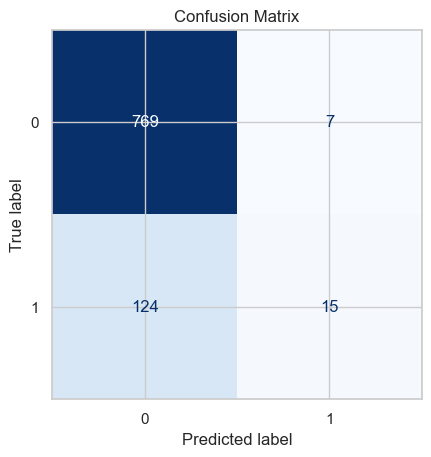

In [13]:
# 50% threshold
t = 0.5
baseline_preds = np.zeros_like(y_test_log)

print(f"Train Accuracy: {accuracy_score(y_train_log, train_log_prob >= t)}")
print(f"Test Accuracy: {accuracy_score(y_test_log, test_log_prob >= t)}")
print(f"Baseline Accuracy: {accuracy_score(y_test_log, baseline_preds)}")


tn, fp, fn, tp = confusion_matrix(y_test_log, test_log_prob > t).ravel()

# Plot the confusion matrix on the test set
cm = confusion_matrix(y_test_log, test_log_prob>t)
print(cm)



plt.figure(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap="Blues", values_format="d", colorbar=False)
plt.title('Confusion Matrix')
plt.show()

Test AUC: 0.7340447229844989


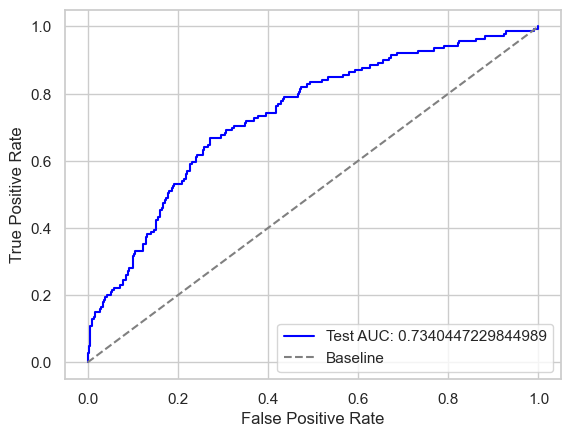

In [14]:

fpr, tpr, _ = roc_curve(y_test_log, test_log_prob)

# print AUC score

print(f"Test AUC: {roc_auc_score(y_test_log, test_log_prob)}")

# roc curve
plt.plot(fpr, tpr, color='blue', label=f"Test AUC: {roc_auc_score(y_test_log, test_log_prob)}")
plt.plot([0, 1], [0, 1], linestyle='--', color='grey', label="Baseline")

# axis labels
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
# show the legend
plt.legend(loc="lower right")
# show the plot
plt.show()



In [15]:
# Comparing performance across threshold

results = []

for t in (0.5, 0.3, 0.15):
    tn, fp, fn, tp = confusion_matrix(y_test_log, test_log_prob > t).ravel()
    total_chd = tp + fn
    results.append({
        'Threshold': t,
        'CHD Caught (True Positives)': tp,
        'CHD Missed (False Negatives)': fn,
        'Healthy Flagged (False Positives)': fp,
        'Healthy Saved (True Negatives)': tn,
        'Sensitivity (Catch Rate)': f"{(tp / total_chd):.1%}"
    })
    
display(pd.DataFrame(results))
    

,Threshold,CHD Caught (True Positives),CHD Missed (False Negatives),Healthy Flagged (False Positives),Healthy Saved (True Negatives),Sensitivity (Catch Rate)
0,0.50,15,124,7,769,10.8%
1,0.30,36,103,68,708,25.9%
2,0.15,98,41,254,522,70.5%


### Clinical Summary & Model Interpretability

#### Key Risk Factors for 10-Year CHD
Based on our logistic regression analysis of the Framingham dataset, the following factors are key drivers of ten-year Coronary Heart Disease (CHD) risk:
* **Demographics & Medical History:** Being **male** (OR ≈ 1.54) and having **prevalent hypertension** (OR ≈ 1.48) or a **prevalent stroke** (OR ≈ 1.17) significantly increase the odds of developing CHD.
* **Physiological Markers:** Increases in **age** (OR ≈ 1.06 per year), **glucose levels**, **total cholesterol**, and **blood pressure medication usage** also act as positive risk indicators.

#### Why Interpretability Matters over "Black Boxes"
In clinical practice, an interpretable model is far easier to trust and adopt than a black box for several reasons:
1. **Transparency in Decision-Making:** Instead of just outputting a risk percentage, this model provides clear, logical risk multipliers (Odds Ratios). Clinicians can easily see *why* a patient is flagged as high-risk.
2. **Actionable Patient Communication:** Clinicians can directly explain to patients how modifying specific lifestyle factors (such as reducing blood pressure or managing cholesterol) will quantitatively lower their risk score.
3. **Clinical Safety Verification:** Because the model's logic is visible, healthcare providers can verify that the predictions align with established physiological principles, preventing errors caused by anomalous data patterns.

## **Stage 4: *Foundations of Clustering***

In [16]:
data = framingham[['age', 'BMI', 'sysBP', 'diaBP', 'totChol', 'glucose', 'heartRate']]
data.describe()


,age,BMI,sysBP,diaBP,totChol,glucose,heartRate
count,3658.000000,3658.000000,3658.000000,3658.000000,3658.000000,3658.000000,3658.000000
mean,49.551941,25.782802,132.370558,82.917031,236.847731,81.852925,75.730727
std,8.562029,4.065601,22.086866,11.974258,44.097681,23.904164,11.981525
min,32.000000,15.540000,83.500000,48.000000,113.000000,40.000000,44.000000
25%,42.000000,23.080000,117.000000,75.000000,206.000000,71.000000,68.000000
50%,49.000000,25.380000,128.000000,82.000000,234.000000,78.000000,75.000000
75%,56.000000,28.037500,143.875000,90.000000,263.000000,87.000000,82.000000
max,70.000000,56.800000,295.000000,142.500000,600.000000,394.000000,143.000000


<function matplotlib.pyplot.show(close=None, block=None)>

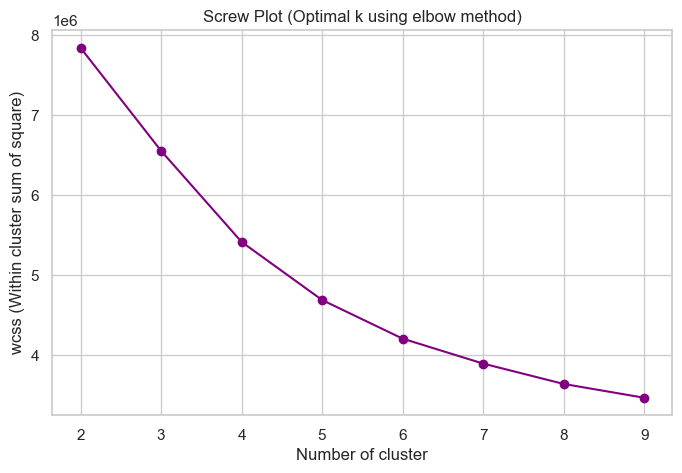

In [17]:
# Normalize the metrics
scalar = MinMaxScaler()
data_norm = scalar.fit_transform(data)
data_scaled = pd.DataFrame(data_norm, columns=data.columns)

# Find optimal k using elbow method
cluster_range = range(2,10)

wcss = []
for k in cluster_range:
    kmeans = KMeans(n_clusters=k, random_state=seed, n_init=10)
    kmeans.fit(data)
    wcss.append(kmeans.inertia_)
    

# plot the elbow method
plt.figure(figsize=(8,5))
plt.plot(cluster_range, wcss, color='purple', marker='o')
plt.xlabel("Number of cluster")
plt.ylabel("wcss (Within cluster sum of square)")
plt.title("Screw Plot (Optimal k using elbow method)")
plt.show

In [18]:
np.random.seed(seed)

# Run the kmeans algorithm for 4 clusters
k = 4
kmeans_Optimal =KMeans(n_clusters=k, random_state=seed, n_init=10)
cluster_labels = kmeans_Optimal.fit_predict(data_norm)


# Add cluster labels to raw data to calculate centroids in original units
clustering_data_with_labels = data.copy()
clustering_data_with_labels['Cluster'] = cluster_labels

# Calculate mean of metrics in original units per cluster
centroids_org = clustering_data_with_labels.groupby('Cluster').mean()

display(centroids_org)

,age,BMI,sysBP,diaBP,totChol,glucose,heartRate
Cluster,,,,,,,
0,45.544835,27.438138,138.744041,89.765607,246.295119,81.483541,81.748014
1,59.000000,28.165243,166.619820,98.547748,253.001802,87.936937,79.153153
2,57.288932,25.253164,126.690989,77.849167,245.582762,83.112635,72.579824
3,41.547877,23.917818,116.696503,74.978351,215.026644,78.241465,72.413822


## Hierarchical Clustering

C:\Users\Welcome Sir\AppData\Local\Temp\ipykernel_14400\1138125986.py:5: ClusterWarning: scipy.cluster: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  data_heir = linkage(data_dist, method='ward')


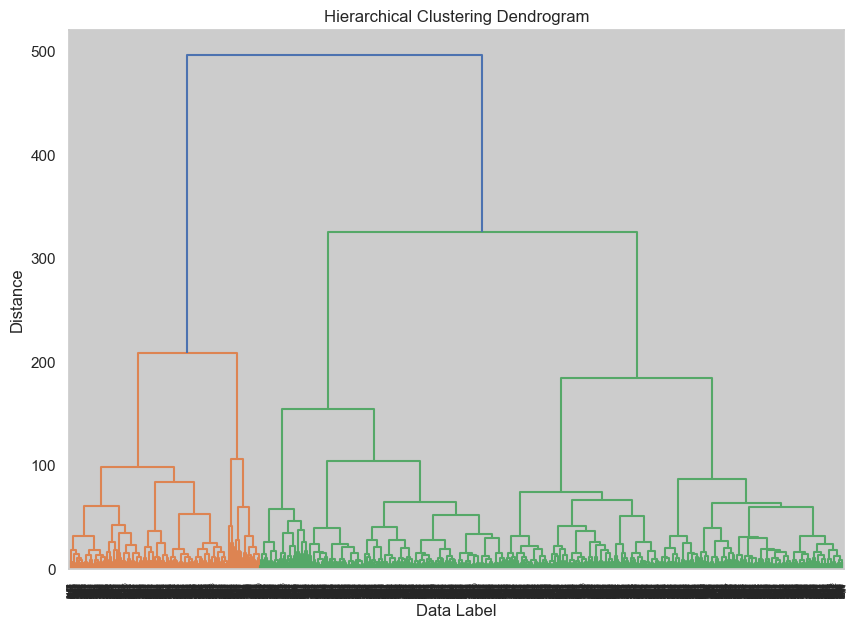

In [19]:
# create distance matrix
data_dist = pairwise_distances(data_norm, metric= 'euclidean')

# Perform hierarchical clustering
data_heir = linkage(data_dist, method='ward')

# plot dendogram
plt.figure(figsize=(10,7))
dendrogram(data_heir)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Label")
plt.ylabel("Distance")
plt.show()



In [20]:
# Cut the dendrogram into 4 clusters
heir_groups = fcluster(data_heir, t=4, criterion="maxclust")


# Number of points in each cluster
print(pd.Series(heir_groups).value_counts())



4    1596
3    1161
1     753
2     148
Name: count, dtype: int64


In [21]:
# Add cluster labels to raw data to calculate centroids in original units
Heirclust_data_with_labels = data.copy()
Heirclust_data_with_labels['Cluster'] = heir_groups
display(Heirclust_data_with_labels.groupby('Cluster').mean())

,age,BMI,sysBP,diaBP,totChol,glucose,heartRate
Cluster,,,,,,,
1,60.763612,26.433931,145.397078,86.430943,253.010624,83.313413,75.115538
2,57.763514,30.709054,181.104730,105.608108,255.756757,122.466216,86.081081
3,40.381568,24.941714,123.304048,79.485357,220.465116,78.637382,77.615848
4,50.171679,25.630620,128.300752,81.651316,239.385965,79.736842,73.689850


### Comparison of Clustering Results

#### Do they find similar groups?
Yes, both algorithms identify very similar underlying patient profiles across their 4 clusters, although the exact group ordering (labels) differs:
* **High-Risk/Hypertensive Group:** Both methods successfully isolate a cluster of older patients with highly elevated blood pressure (mean `sysBP` ~160-166 mmHg, `diaBP` ~98 mmHg).
* **Healthy/Younger Group:** Both isolate a younger cohort with low baseline cardiovascular risk factors (mean `sysBP` ~117 mmHg, `diaBP` ~74 mmHg).
* **Moderate/Borderline Groups:** The remaining clusters capture borderline-hypertensive cohorts with varying balances of age, BMI, and cholesterol.

---

### Strengths and Limitations of Each Method

#### 1. K-Means Clustering
* **Strength:** Extremely fast and computationally efficient, making it highly scalable to very large datasets.
* **Limitation:** Requires the user to specify the number of clusters ($k$) in advance, and can get stuck in local optima depending on the initial centroid placement.

#### 2. Hierarchical (Ward's) Clustering
* **Strength:** Does not require pre-specifying the number of clusters beforehand and provides a highly intuitive dendrogram visualization to help choose natural groupings.
* **Limitation:** Highly computationally expensive and memory-intensive ($O(N^2)$ to $O(N^3)$ complexity), making it impractical for massive datasets.

## **Stage 5: *Explaining Clusters with a Decision Tree Classifier***

In [22]:
# Prepare features (original unscaled units) and targets (k-means labels)
X_tree = data
y_tree = cluster_labels

# fit decision tree
model_tree = DecisionTreeClassifier(max_depth=3, random_state=seed)
model_tree.fit(X_tree, y_tree)

# Evaluate accuracy in predicting clusters
tree_pred = model_tree.predict(X_tree)
tree_accuracy = accuracy_score(y_tree, tree_pred)
print(f"Decision Tree Accuracy: {tree_accuracy: .2%}")

Decision Tree Accuracy:  85.57%


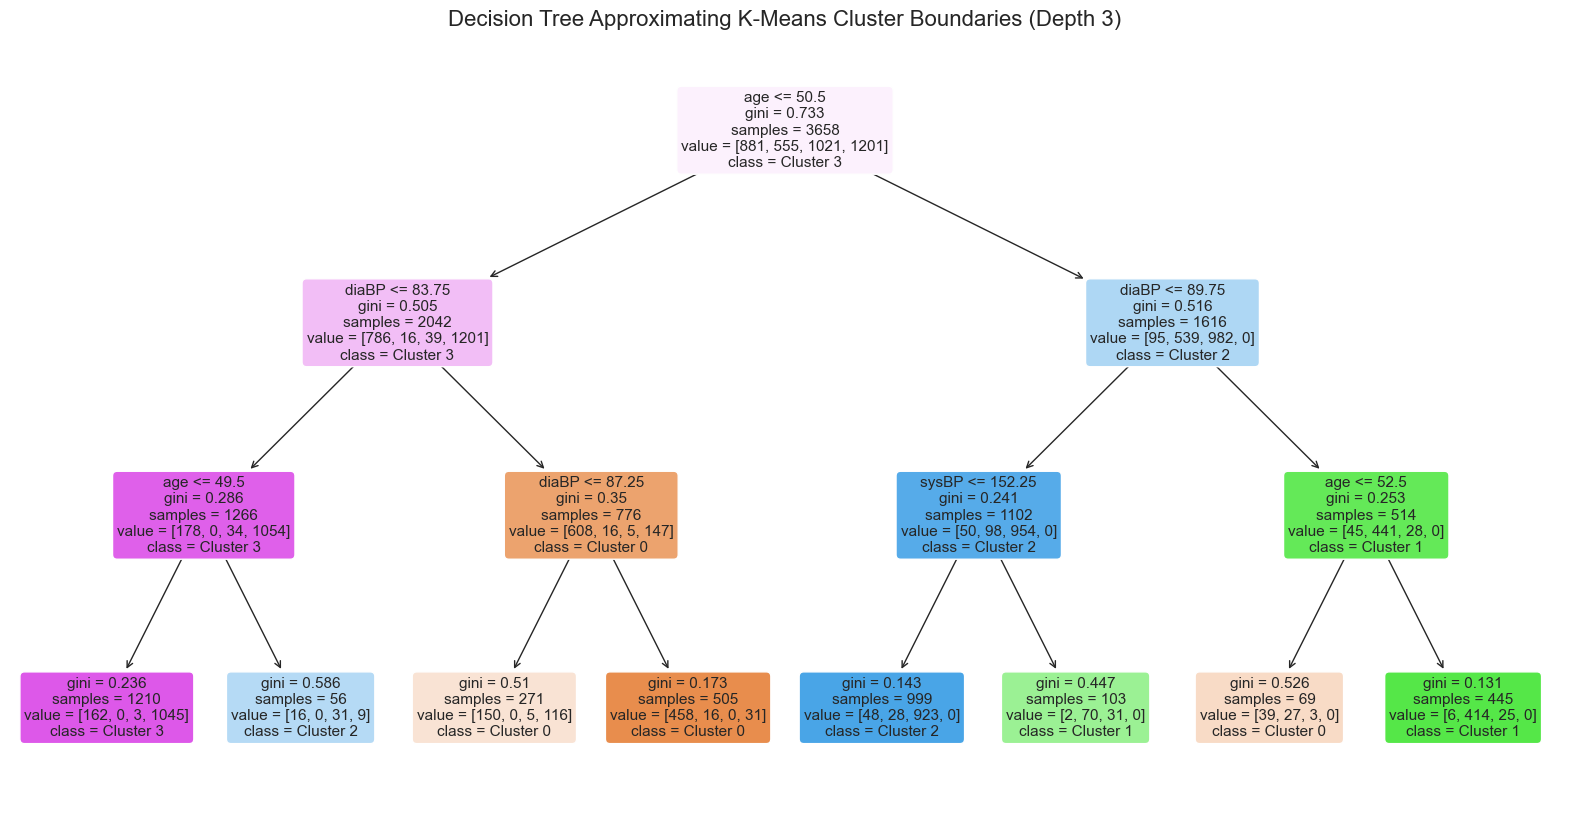

In [23]:
# Visualise Decision Tree

plt.figure(figsize=(20,10))
plot_tree(model_tree,
          feature_names=data.columns,
          class_names=[f"Cluster {i}" for i in range(k)],
          filled=True,
          rounded=True,
          fontsize=11
    )

plt.title("Decision Tree Approximating K-Means Cluster Boundaries (Depth 3)", fontsize=16)
plt.show()

In [27]:
# Export the decision tree rules as text
tree_rules = export_text(model_tree, feature_names=list(data.columns))
print(tree_rules)

|--- age <= 50.50
|   |--- diaBP <= 83.75
|   |   |--- age <= 49.50
|   |   |   |--- class: 3
|   |   |--- age >  49.50
|   |   |   |--- class: 2
|   |--- diaBP >  83.75
|   |   |--- diaBP <= 87.25
|   |   |   |--- class: 0
|   |   |--- diaBP >  87.25
|   |   |   |--- class: 0
|--- age >  50.50
|   |--- diaBP <= 89.75
|   |   |--- sysBP <= 152.25
|   |   |   |--- class: 2
|   |   |--- sysBP >  152.25
|   |   |   |--- class: 1
|   |--- diaBP >  89.75
|   |   |--- age <= 52.50
|   |   |   |--- class: 0
|   |   |--- age >  52.50
|   |   |   |--- class: 1



In [24]:
# Calculate CHD rate per cluster
chd_rates = framingham.groupby(cluster_labels)['TenYearCHD'].agg(['count', 'sum', 'mean'])
chd_rates.columns = ['Total Patients', 'CHD Cases', 'CHD Rate']
chd_rates['CHD Rate'] = chd_rates['CHD Rate'].map(lambda x: f"{x:.2%}")
display(chd_rates)

,Total Patients,CHD Cases,CHD Rate
0,881,108,12.26%
1,555,184,33.15%
2,1021,190,18.61%
3,1201,75,6.24%
